# 02. Мультимодальна інженерія ознак, відбір і пастка витоку


| Розділ | Пункт ТЗ |
|---|---|
| 0. Препроцесор ЛР №1 і протокол верифікації | Порядок дій, крок 1 |
| 1. Розбиття (одне на всю роботу) і нульовий рядок | крок 2 |
| 2. Експеримент 1 — Baseline | п. 4.4 |
| 3. Крок 1: ручні ознаки, Експеримент 2 | п. 4.1, кроки 3–4 |
| 4. Крок 2: екстракція та перевірка інформативності | п. 4.2, кроки 5–6 |
| 5. Крок 3: DFS, вибух розмірності, повторна перевірка захищених ознак | п. 4.3, кроки 7–8 |
| 6. Базова статистика до формального відбору | п. 4.5 |
| 7. Експеримент 3 — чесний відбір усередині train | крок 9 |
| 8. **Експеримент 4 — навмисний витік** | п. 4.4, крок 10 |
| 9. Таблиця п'яти експериментів | п. 4.4 |
| 10. DPR / EOR для Експериментів 1 і 4 | крок 11 |
| 11. Трирівнева воронка відбору | п. 4.5, крок 12 |
| 12. Дані для REFORMS 3f | п. 5 |



In [1]:
import sys, json, time, warnings, subprocess, tempfile, copy
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "pipeline.py").exists())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
from sklearn.base import clone

from src.lab1 import LAB1_DIR, LAB1_SHA256, file_sha256
from src.pipeline import DynamicPipelineBuilder, model_pipeline, load_config, fairness_report, transformed_frame, readable_names
from src.selection import hybrid_selector, basic_statistics, vif_table, SelectionFunnel
from src.features import woe_table

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)
ART, FIG = ROOT / "artifacts", ROOT / "artifacts" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3",
    "axes.labelcolor": "#52514e", "text.color": "#0b0b0b", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10, "axes.axisbelow": True,
})

CFG = {
    "lab1_lr": LAB1_DIR / "config/config_lr.yaml", "lab1_rf": LAB1_DIR / "config/config_rf.yaml",
    "manual_lr": ROOT / "config/stage2_manual_lr.yaml", "manual_rf": ROOT / "config/stage2_manual_rf.yaml",
    "full_lr": ROOT / "config/config_lr.yaml", "full_rf": ROOT / "config/config_rf.yaml",
}
full = load_config(CFG["full_lr"])
EXP, FAIR, SEL = full["experiment"], full["fairness"], full["selection"]

def LR():
    return LogisticRegression(max_iter=1000)
def RF():
    return RandomForestClassifier(n_estimators=200, random_state=EXP["random_state"], n_jobs=-1)
MODELS = {"LR": LR, "RF": RF}

## 0. Препроцесор ЛР №1 і протокол верифікації (крок 1)



In [ ]:
print("SHA-256 модуля ЛР №1 збігається з зафіксованим:", file_sha256() == LAB1_SHA256)
r = subprocess.run([sys.executable, "run_verification.py"], cwd=LAB1_DIR, capture_output=True, text=True)
print("ЛР №1 →", r.stdout.strip(), "| exit", r.returncode)
r = subprocess.run([sys.executable, "run_verification.py"], cwd=ROOT, capture_output=True, text=True)
print("ЛР №2 →", r.stdout.strip(), "| exit", r.returncode)

## 1. Дані, єдине розбиття і нульовий рядок


In [ ]:
data = pd.read_csv(ROOT / "data/processed/dataset.csv")
y = data["bad_credit"].to_numpy()
X = data.drop(columns="bad_credit")
manifest = json.loads((ROOT / "data/processed/build_manifest.json").read_text())
print("набір:", X.shape, "| частка bad:", y.mean().round(3))

idx_train, idx_test = train_test_split(np.arange(len(X)), test_size=EXP["test_size"], stratify=y,
                                       random_state=EXP["random_state"])
X_train, X_test, y_train, y_test = X.iloc[idx_train], X.iloc[idx_test], y[idx_train], y[idx_test]
sex_test = X_test[FAIR["attribute"]].to_numpy()
print("train:", X_train.shape, " test:", X_test.shape)

### Рядок 0 — Non-ML Heuristic (з ЛР №1)


In [4]:
clean = pd.read_csv(LAB1_DIR / "data/processed/german_credit_clean.csv")
rule = ((clean["checking_account"] == "<0 DM") |
        ((clean["duration"] > 24) & (clean["savings_account"] == "<100 DM"))).astype(int).to_numpy()
lab1_bench = json.loads((LAB1_DIR / "artifacts/heuristic_benchmark.json").read_text())["heuristic"]
auc_heuristic_full = roc_auc_score(y, rule)
auc_heuristic_test = roc_auc_score(y_test, rule[idx_test])
print(f"ЛР №1 (усі 1000): Accuracy={lab1_bench['accuracy']:.3f}, Recall(bad)={lab1_bench['recall_bad']:.3f}, "
      f"Precision(bad)={lab1_bench['precision_bad']:.3f}, ROC-AUC={auc_heuristic_full:.4f}")
print(f"ROC-AUC евристики на тих самих 300 test-заявках: {auc_heuristic_test:.4f}")

ЛР №1 (усі 1000): Accuracy=0.693, Recall(bad)=0.580, Precision(bad)=0.490, ROC-AUC=0.6607
ROC-AUC евристики на тих самих 300 test-заявках: 0.6897


In [5]:
def bootstrap_ci(y_true, score, n_boot=1000, seed=0):
    rng = np.random.default_rng(seed)
    stats = []
    for _ in range(n_boot):
        i = rng.integers(0, len(y_true), len(y_true))
        if y_true[i].min() != y_true[i].max():
            stats.append(roc_auc_score(y_true[i], score[i]))
    return np.percentile(stats, [2.5, 97.5])

RESULTS, PRED = [], {}
def record(exp, model, p_bad, n_features, note=""):
    lo, hi = bootstrap_ci(y_test, p_bad)
    RESULTS.append({"experiment": exp, "model": model, "roc_auc": roc_auc_score(y_test, p_bad),
                    "ci_low": lo, "ci_high": hi, "n_features": n_features, "note": note})
    PRED[(exp, model)] = p_bad
    print(f"{exp:28s} {model}: ROC-AUC = {RESULTS[-1]['roc_auc']:.4f}  [95% CI {lo:.3f}–{hi:.3f}], ознак: {n_features}")

record("0. Non-ML Heuristic", "—", rule[idx_test].astype(float), 3, "правило ЛР №1, без навчання")

0. Non-ML Heuristic          —: ROC-AUC = 0.6897  [95% CI 0.629–0.747], ознак: 3


## 2. Експеримент 1 — Baseline



In [6]:
FITTED = {}
for model, cfg in (("LR", CFG["lab1_lr"]), ("RF", CFG["lab1_rf"])):
    pipe = model_pipeline(cfg, MODELS[model]()).fit(X_train, y_train)
    FITTED[("1. Baseline", model)] = pipe
    n = len(pipe.named_steps["prep"].get_feature_names_out())
    record("1. Baseline", model, pipe.predict_proba(X_test)[:, 1], n, "конфігурація ЛР №1")

1. Baseline                  LR: ROC-AUC = 0.7997  [95% CI 0.742–0.851], ознак: 19


1. Baseline                  RF: ROC-AUC = 0.7739  [95% CI 0.717–0.826], ознак: 50


## 3. Крок 1 — ручні ознаки (п. 4.1)

| Категорія | Трансформер (`src/features.py`) | Де застосовано |
|---|---|---|
| А. Часові | `CyclicTimeTransformer` (sin/cos) | German Credit не має часової колонки → дата скарги CFPB (місяць, день тижня), Експ. 3 |
| Б. Взаємодії | `InteractionTransformer`: `credit_amount/duration` (щомісячне навантаження), `duration/age` + `yeo_johnson` (additive) | Експ. 2–4 |
| В. Висока кардинальність | `OOFWoEEncoder` (out-of-fold WoE) | номінальні German (additive) і компанія CFPB (обидві родини), Експ. 2–4 |




In [7]:
from src.features import CyclicTimeTransformer, InteractionTransformer, OOFWoEEncoder
demo = pd.DataFrame({"complaint_month": [11, 12, 1, 2, 6]})
print(CyclicTimeTransformer(periods={"complaint_month": 12}, drop_original=False).fit_transform(demo).round(3))
demo = X_train[["credit_amount", "duration", "age"]].dropna().head(3)
print(InteractionTransformer(ratios=[["credit_amount", "duration"], ["duration", "age"]]).fit_transform(demo).round(2))

   complaint_month  complaint_month_sin  complaint_month_cos
0               11               -0.500                0.866
1               12               -0.000                1.000
2                1                0.500                0.866
3                2                0.866                0.500
4                6                0.000               -1.000
     credit_amount  duration   age  credit_amount_div_duration  duration_div_age
10          1295.0        12  25.0                      107.92              0.48
410         1967.0        24  20.0                       81.96              1.20
48          7228.0        11  39.0                      657.09              0.28


### В. Чому WoE потребує регуляризації: приклад ТЗ і вада звичайного WoE



In [8]:
m = X_train["purpose"].notna()
t = woe_table(X_train.loc[m, "purpose"].to_numpy(), y_train[m.to_numpy()], smoothing=0.5)
t.loc[["radio/television", "education", "car (new)", "business"]].round(3)

,n,woe,iv
row_0,,,
radio/television,144,0.368,0.033
education,30,-1.094,0.077
car (new),124,-0.135,0.004
business,55,-0.285,0.009


In [9]:
company_counts = X_train["complaint_company"].value_counts()
print(f"complaint_company у train: {company_counts.size} компаній, {int((company_counts == 1).sum())} трапляються один раз")

enc = OOFWoEEncoder(n_splits=5, smoothing=0.5, random_state=42)
oof_codes = enc.fit_transform(X_train[["complaint_company"]], y_train)[:, 0]
plain_codes = enc.transform(X_train[["complaint_company"]])[:, 0]
single = X_train["complaint_company"].map(company_counts).to_numpy() == 1
print("Рядки з унікальною компанією (train):")
print(f"  звичайний WoE: AUC коду щодо власної мітки = {roc_auc_score(y_train[single], -plain_codes[single]):.3f}")
print(f"  OOF WoE:       AUC коду щодо власної мітки = {roc_auc_score(y_train[single], -oof_codes[single]):.3f}"
      f"  (усі коди = {np.unique(oof_codes[single].round(6))})")

complaint_company у train: 178 компаній, 95 трапляються один раз
Рядки з унікальною компанією (train):
  звичайний WoE: AUC коду щодо власної мітки = 1.000
  OOF WoE:       AUC коду щодо власної мітки = 0.500  (усі коди = [0.])




Абляція на моделі: та сама конфігурація з `woe` ЛР №1 замість `oof_woe` для компанії.

In [10]:
def with_policy(cfg_path, group, steps):
    cfg = load_config(cfg_path)
    for fam in cfg["transform_policy"]:
        cfg["transform_policy"][fam][group] = steps
    f = tempfile.NamedTemporaryFile("w", suffix=".yaml", delete=False, encoding="utf-8")
    yaml.safe_dump(cfg, f, allow_unicode=True); f.close()
    return f.name

ablation = []
for label, path in (("woe (ЛР №1, без регуляризації)", with_policy(CFG["full_lr"], "high_cardinality", [{"woe": {"smoothing": 0.5}}])),
                    ("oof_woe (ЛР №2)", str(CFG["full_lr"]))):
    p = model_pipeline(path, LR()).fit(X_train, y_train)
    ablation.append({"кодування компанії": label,
                     "AUC train": roc_auc_score(y_train, p.predict_proba(X_train)[:, 1]),
                     "AUC test": roc_auc_score(y_test, p.predict_proba(X_test)[:, 1])})
pd.DataFrame(ablation).round(4)

,кодування компанії,AUC train,AUC test
0,"woe (ЛР №1, без регуляризації)",0.9298,0.6874
1,oof_woe (ЛР №2),0.8654,0.7406


### Експеримент 2 — Manual FE


In [11]:
for model, cfg in (("LR", CFG["manual_lr"]), ("RF", CFG["manual_rf"])):
    pipe = model_pipeline(cfg, MODELS[model]()).fit(X_train, y_train)
    FITTED[("2. Manual FE", model)] = pipe
    n = len(pipe.named_steps["prep"].get_feature_names_out())
    record("2. Manual FE", model, pipe.predict_proba(X_test)[:, 1], n, "+ interactions, Yeo-Johnson, OOF WoE")

2. Manual FE                 LR: ROC-AUC = 0.7796  [95% CI 0.720–0.833], ознак: 21


2. Manual FE                 RF: ROC-AUC = 0.7891  [95% CI 0.731–0.844], ознак: 52


### Звідки спад LR в Експ. 2? Абляція компонентів

Та сама конфігурація Експ. 2 (LR), з якої по черзі прибрано один компонент Кроку 1.

In [12]:
def manual_variant(update):
    cfg = load_config(CFG["manual_lr"]); update(cfg["transform_policy"]["additive"])
    f = tempfile.NamedTemporaryFile("w", suffix=".yaml", delete=False, encoding="utf-8")
    yaml.safe_dump(cfg, f, allow_unicode=True); f.close()
    p = model_pipeline(f.name, LR()).fit(X_train, y_train)
    return roc_auc_score(y_test, p.predict_proba(X_test)[:, 1])

ratios = load_config(CFG["manual_lr"])["transform_policy"]["additive"]["numeric_continuous"][0]
variants = {
    "Експ. 2 як є": lambda t: None,
    "номінальні German: woe ЛР №1 замість oof_woe": lambda t: t.update(categorical_nominal=[{"woe": {"smoothing": 0.5}}]),
    "числові: log1p + scaler замість Yeo-Johnson": lambda t: t.update(numeric_continuous=[ratios, "log1p", "standard_scaler"]),
    "без взаємодій (лише Yeo-Johnson)": lambda t: t.update(numeric_continuous=[{"yeo_johnson": {"standardize": True}}]),
}
abl2 = pd.DataFrame({"варіант": list(variants), "AUC test (LR)": [manual_variant(f) for f in variants.values()]})
abl2.to_csv(ART / "ablation_manual_fe.csv", index=False)
abl2.round(4)

,варіант,AUC test (LR)
0,Експ. 2 як є,0.7796
1,номінальні German: woe ЛР №1 замість oof_woe,0.8024
2,числові: log1p + scaler замість Yeo-Johnson,0.7761
3,без взаємодій (лише Yeo-Johnson),0.7784


## 4. Крок 2 — мультимодальна екстракція (п. 4.2)


In [13]:
print("Сигнал:", manifest["signal_report"])
print("Текст: порожніх після очищення —", manifest["text_corpus"]["empty_after_cleaning"],
      "| пул скарг Consumer Loan з текстом:", manifest["text_corpus"]["pool_size"])
X_train[[c for c in X.columns if c.startswith("sig_")]].describe().T[["count", "mean", "std", "min", "max"]].round(3).head(6)

Сигнал: {'total': 1000, 'empty': 18, 'too_short': 3, 'padded': 305, 'nonfinite_removed': 3}
Текст: порожніх після очищення — 0 | пул скарг Consumer Loan з текстом: 3678


,count,mean,std,min,max
sig_zcr,681.0,0.176,0.169,0.000,0.715
sig_centroid,681.0,1.936,0.504,0.000,3.255
sig_mfcc0,681.0,49.148,39.213,-400.000,146.310
sig_mfcc1,681.0,7.714,5.957,-9.219,26.652
sig_mfcc2,681.0,-35.298,6.385,-53.592,0.000
sig_mfcc3,681.0,0.221,3.113,-8.816,16.489


Теми LSA, навчені на train (5 слів з найбільшою вагою в кожній компоненті):

In [14]:
from src.extraction import TextExtractor
tx = TextExtractor(max_features=500, n_components=5, random_state=42).fit(X_train[["complaint_text"]])
vocab = np.array(tx.vectorizer_.get_feature_names_out())
for i, comp in enumerate(tx.svd_.components_):
    print(f"svd{i}: " + ", ".join(vocab[np.argsort(-comp)[:5]]))
print("частка дисперсії TF-IDF, пояснена 5 компонентами:", tx.svd_.explained_variance_ratio_.sum().round(3))

svd0: loan, payment, credit, car, account
svd1: credit, report, account, reporting, hard
svd2: payment, account, late, fee, bank
svd3: calls, company, calling, phone, number
svd4: loan, wells, fargo, bank, rate
частка дисперсії TF-IDF, пояснена 5 компонентами: 0.08


### Перевірка інформативності перед DFS (AIC / псевдо-R²)

Проста модель — логістична регресія statsmodels на train. База — простір Експерименту 2 (additive). Порівнюємо AIC, McFadden R² і тест відношення правдоподібності (LR-test) після додавання блоку. Усі перетворення навчаються на train.

In [15]:
import statsmodels.api as sm
from scipy.stats import chi2
from sklearn.preprocessing import StandardScaler
from src.extraction import SignalExtractor, sequences_by_key

base_prep = DynamicPipelineBuilder(str(CFG["manual_lr"])).build().fit(X_train, y_train)
B = base_prep.transform(X_train)

def text_block(n_components):
    t = TextExtractor(max_features=500, n_components=n_components, random_state=42)
    return StandardScaler().fit_transform(t.fit_transform(X_train[["complaint_text"]]))

from src.lab1 import lab1
def signal_block(frame):
    imputed = lab1.AdaptiveImputer(full["imputation_policy"]["numeric"]).fit_transform(frame.reset_index(drop=True))
    return StandardScaler().fit_transform(imputed)

sig_cols = [c for c in X.columns if c.startswith("sig_")]
from statsmodels.tools.sm_exceptions import ConvergenceWarning
def logit_stats(M):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        res = sm.Logit(y_train, sm.add_constant(M)).fit(disp=0, maxiter=1000)
    return res.llf, res.aic, res.prsquared, M.shape[1], bool(res.mle_retvals["converged"])

base = logit_stats(B)
rows = [{"блок": "база (Експ. 2)", "k": base[3], "AIC": base[1], "McFadden R²": base[2], "LR-test p": np.nan,
         "збіжність": base[4]}]
def add(name, block):
    s = logit_stats(np.hstack([B, block]))
    p = chi2.sf(2 * (s[0] - base[0]), s[3] - base[3])
    rows.append({"блок": name, "k": s[3], "AIC": s[1], "McFadden R²": s[2], "LR-test p": p, "збіжність": s[4]})

add("+ текст LSA, n_components=5", text_block(5))
add("+ сигнал, n_mfcc=13", signal_block(X_train[sig_cols]))
info = pd.DataFrame(rows)
info.round(4)

,блок,k,AIC,McFadden R²,LR-test p,збіжність
0,база (Експ. 2),21,704.0132,0.2282,NaN,True
1,"+ текст LSA, n_components=5",26,709.7933,0.2332,0.5182,True
2,"+ сигнал, n_mfcc=13",36,715.4963,0.2452,0.4867,False


In [16]:
events = pd.read_csv(ROOT / "data/external/hc_installments_sample.csv")
src_cfg = load_config(ROOT / "config/sources.yaml")["signal"]
seqs = sequences_by_key(events, X["source_sk_id_curr"].tolist(), "SK_ID_CURR", src_cfg["value"], src_cfg["order"])
for n_comp in (10, 20):
    add(f"+ текст LSA, n_components={n_comp}", text_block(n_comp))
params = dict(src_cfg["extractor"], n_mfcc=20, n_mels=24)
sig20 = SignalExtractor(**params).fit().transform([seqs[k] for k in X_train["source_sk_id_curr"]])
add("+ сигнал, n_mfcc=20", signal_block(sig20))
info = pd.DataFrame(rows)
info.to_csv(ART / "informativeness.csv", index=False)
info.round(4)

,блок,k,AIC,McFadden R²,LR-test p,збіжність
0,база (Експ. 2),21,704.0132,0.2282,NaN,True
1,"+ текст LSA, n_components=5",26,709.7933,0.2332,0.5182,True
2,"+ сигнал, n_mfcc=13",36,715.4963,0.2452,0.4867,False
3,"+ текст LSA, n_components=10",31,713.4703,0.2406,0.3942,True
4,"+ текст LSA, n_components=20",41,720.0768,0.2562,0.2452,True
5,"+ сигнал, n_mfcc=20",43,715.4987,0.2452,0.8822,False


## 5. Крок 3 — AutoFE: Featuretools DFS (п. 4.3)


In [17]:
lineage = json.loads((ROOT / "data/processed/dfs_lineage.json").read_text())
d = manifest["dfs"]
print(f"Вхід DFS: {d['input_features']} ознак → вихід: {d['output_features']} (×{d['output_features']/d['input_features']:.1f}); "
      f"нових: {d['new_features']}")
pd.DataFrame(lineage)[["name", "definition"]].sample(8, random_state=1)

Вхід DFS: 23 ознак → вихід: 147 (×6.4); нових: 129


,name,definition
122,NATURAL_LOGARITHM_COUNT_payments,NATURAL_LOGARITHM(COUNT(payments))
104,age_div_MAX_payments_NUM_INSTALMENT_NUMBER,age / MAX(payments.NUM_INSTALMENT_NUMBER)
55,MAX_payments_AMT_INSTALMENT_div_duration,MAX(payments.AMT_INSTALMENT) / duration
56,MAX_payments_AMT_PAYMENT_div_COUNT_payments,MAX(payments.AMT_PAYMENT) / COUNT(payments)
33,MEAN_payments_NATURAL_LOGARITHM_AMT_INSTALMENT,MEAN(payments.NATURAL_LOGARITHM(AMT_INSTALMENT))
119,duration_div_MEAN_payments_AMT_INSTALMENT,duration / MEAN(payments.AMT_INSTALMENT)
123,NATURAL_LOGARITHM_MAX_payments_AMT_INSTALMENT,NATURAL_LOGARITHM(MAX(payments.AMT_INSTALMENT))
35,MEAN_payments_NATURAL_LOGARITHM_NUM_INSTALMENT...,MEAN(payments.NATURAL_LOGARITHM(NUM_INSTALMENT...


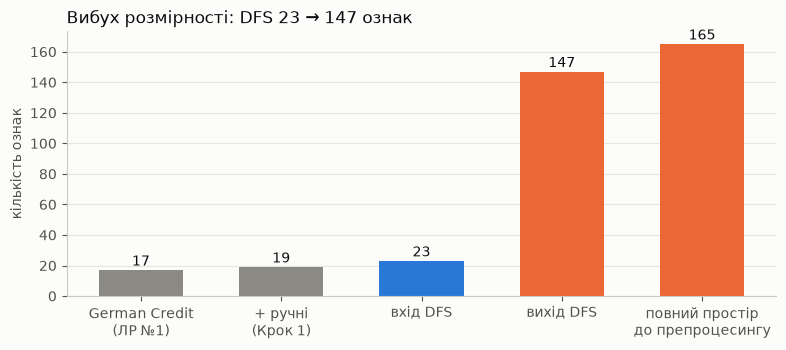

In [18]:
n_lab1 = sum(len(v) for v in load_config(CFG["lab1_lr"])["features"].values())
n_ratios = len(load_config(CFG["manual_lr"])["transform_policy"]["additive"]["numeric_continuous"][0]["interactions"]["ratios"])
space = {
    "German Credit\n(ЛР №1)": n_lab1,
    "+ ручні\n(Крок 1)": n_lab1 + n_ratios,
    "вхід DFS": d["input_features"],
    "вихід DFS": d["output_features"],
    "повний простір\nдо препроцесингу": len([c for cols in full["features"].values() for c in cols]),
}
fig, ax = plt.subplots(figsize=(8, 3.6))
bars = ax.bar(list(space), list(space.values()), color=[GRAY, GRAY, BLUE, ORANGE, ORANGE], width=0.6)
for b, v in zip(bars, space.values()):
    ax.text(b.get_x() + b.get_width() / 2, v + 3, str(v), ha="center", color="#0b0b0b")
ax.set_ylabel("кількість ознак"); ax.grid(axis="x", visible=False)
ax.set_title(f"Вибух розмірності: DFS {d['input_features']} → {d['output_features']} ознак", loc="left")
fig.tight_layout(); fig.savefig(FIG / "dfs_feature_explosion.png", dpi=130); plt.show()

### Повторна перевірка захищених ознак після DFS (CACE)


In [19]:
from run_verification import test_protected_excluded, test_protected_not_in_dfs_lineage, test_idempotent
for key in ("full_lr", "full_rf"):
    test_idempotent(str(CFG[key])); test_protected_excluded(str(CFG[key]))
print("test_idempotent + test_protected_excluded: OK для config_lr і config_rf")
print("ознак DFS перевірено за родоводом:", test_protected_not_in_dfs_lineage(str(CFG["full_lr"])))

age_based = [e["name"] for e in lineage if "clients.age" in e["base_columns"]]
print(f"ознак DFS, побудованих з age: {len(age_based)}")

test_idempotent + test_protected_excluded: OK для config_lr і config_rf
ознак DFS перевірено за родоводом: 129
ознак DFS, побудованих з age: 19


In [20]:
female = (X_train[FAIR["attribute"]] != FAIR["privileged"]).to_numpy().astype(int)
dfs_names = [e["name"] for e in lineage]
cand = X_train[dfs_names + sig_cols + ["duration", "credit_amount", "age"]]
assoc = cand.apply(lambda c: abs(roc_auc_score(female[c.notna().to_numpy()], c.dropna()) - 0.5) * 2)
assoc = assoc.sort_values(ascending=False).rename("|2·AUC−1| зі статтю")
src_of = {e["name"]: ", ".join(b.split(".")[1] for b in e["base_columns"]) for e in lineage}
top = assoc.head(10).to_frame()
top["побудовано з"] = [src_of.get(n, "базова ознака") for n in top.index]
top.round(3)

,|2·AUC−1| зі статтю,побудовано з
NATURAL_LOGARITHM_age,0.199,age
age,0.199,базова ознака
NATURAL_LOGARITHM_credit_amount,0.103,credit_amount
credit_amount,0.103,базова ознака
NATURAL_LOGARITHM_duration,0.086,duration
duration,0.086,базова ознака
MEAN_payments_NUM_INSTALMENT_NUMBER_div_AMT_INSTALMENT,0.079,"AMT_INSTALMENT, NUM_INSTALMENT_NUMBER"
credit_amount_div_duration,0.078,"credit_amount, duration"
duration_div_credit_amount,0.078,"credit_amount, duration"
age_div_MEAN_payments_AMT_PAYMENT,0.077,"age, AMT_PAYMENT"


In [21]:
sex_auc = {}
for label, cfg in (("простір ЛР №1", CFG["lab1_lr"]), ("повний простір ЛР №2", CFG["full_lr"])):
    p = model_pipeline(cfg, LR()).fit(X_train, female)
    sex_auc[label] = roc_auc_score((X_test[FAIR["attribute"]] != FAIR["privileged"]).astype(int), p.predict_proba(X_test)[:, 1])
    print(f"{label}: стать передбачається з AUC = {sex_auc[label]:.3f}")

простір ЛР №1: стать передбачається з AUC = 0.674


повний простір ЛР №2: стать передбачається з AUC = 0.642


## 6. Базова статистика до формального відбору (п. 4.5)


In [22]:
prep_full = DynamicPipelineBuilder(str(CFG["full_lr"])).build()
Z_train = pd.DataFrame(prep_full.fit_transform(X_train, y_train),
                       columns=readable_names(prep_full.get_feature_names_out()), index=X_train.index)
clash = [c for c in Z_train.columns if ":" in c]
print("однакові назви з різних груп (ручні відношення, які DFS згенерував повторно):", clash)
print("r між ними:", {a.split(":")[1]: round(float(np.corrcoef(Z_train[a], Z_train[b])[0, 1]), 3)
                      for a, b in zip(clash[::2], clash[1::2])})
stats = basic_statistics(Z_train, y_train, corr_threshold=SEL["basic"]["threshold"])
print("простір після препроцесингу:", Z_train.shape)
print("майже-константні ознаки:", len(stats["near_constant"]))
print(f"пар із |r| ≥ {SEL['basic']['threshold']}:", len(stats["high_corr_pairs"]))
stats["describe"][["mean", "std", "min", "max"]].round(2).head(8)

однакові назви з різних груп (ручні відношення, які DFS згенерував повторно): ['numeric_continuous:credit_amount_div_duration', 'numeric_continuous:duration_div_age', 'dfs_features:credit_amount_div_duration', 'dfs_features:duration_div_age']
r між ними: {'credit_amount_div_duration': -0.115}
простір після препроцесингу: (700, 194)
майже-константні ознаки: 0
пар із |r| ≥ 0.95: 251


,mean,std,min,max
duration,-0.0,1.0,-2.37,2.19
credit_amount,-0.0,1.0,-3.09,2.66
age,-0.0,1.0,-2.45,2.36
credit_amount_missing,-0.0,1.0,-0.49,2.04
numeric_continuous:credit_amount_div_duration,0.0,1.0,-2.93,3.23
numeric_continuous:duration_div_age,0.0,1.0,-2.11,2.59
installment_rate,-0.0,1.0,-1.73,0.95
residence_since,-0.0,1.0,-0.86,1.65


In [23]:
print("Найсильніший лінійний зв'язок із ціллю (train):")
stats["corr_with_target"].head(12).round(3).to_frame("r з bad_credit")

Найсильніший лінійний зв'язок із ціллю (train):


,r з bad_credit
checking_account,-0.335
credit_history,-0.218
numeric_continuous:duration_div_age,0.212
NATURAL_LOGARITHM_duration,0.206
duration,0.205
age_div_duration,-0.197
dfs_features:duration_div_age,0.196
duration_div_MEAN_payments_AMT_INSTALMENT,0.164
duration_div_MEAN_payments_AMT_PAYMENT,0.158
duration_div_MEAN_payments_NUM_INSTALMENT_NUMBER,0.158


In [24]:
stats["high_corr_pairs"].head(10).round(4)

,level_0,level_1,r
751,credit_amount_missing,NATURAL_LOGARITHM_credit_amount_missing,1.0
750,credit_amount_missing,duration_div_credit_amount_missing,1.0
749,credit_amount_missing,credit_amount_div_duration_missing,1.0
6636,sig_mfcc5,sig_mfcc11,1.0
752,credit_amount_missing,COUNT_payments_div_credit_amount_missing,1.0
11316,MAX_payments_NATURAL_LOGARITHM_AMT_PAYMENT,NATURAL_LOGARITHM_MAX_payments_AMT_PAYMENT,1.0
11193,MAX_payments_NATURAL_LOGARITHM_AMT_INSTALMENT,NATURAL_LOGARITHM_MAX_payments_AMT_INSTALMENT,1.0
11438,MAX_payments_NATURAL_LOGARITHM_NUM_INSTALMENT_...,NATURAL_LOGARITHM_MAX_payments_NUM_INSTALMENT_...,1.0
18670,MAX_payments_NUM_INSTALMENT_NUMBER_div_credit_...,credit_amount_div_MAX_payments_AMT_INSTALMENT_...,1.0
18671,MAX_payments_NUM_INSTALMENT_NUMBER_div_credit_...,credit_amount_div_MAX_payments_AMT_PAYMENT_mis...,1.0


In [25]:
vif = vif_table(Z_train.loc[:, Z_train.std() > 0])
print(f"число обумовленості матриці ознак: {np.linalg.cond(Z_train.to_numpy()):.2e}")
print("VIF > 10:", int((vif > 10).sum()), "з", len(vif), "| VIF = ∞ (точна лінійна залежність):", int(np.isinf(vif).sum()))
vif.head(10).round(1).to_frame()

число обумовленості матриці ознак: 9.31e+67
VIF > 10: 160 з 194 | VIF = ∞ (точна лінійна залежність): 0


,VIF
COUNT_payments_div_credit_amount_missing,25700212.7
credit_amount_div_duration_missing,25700212.7
duration_div_credit_amount_missing,25700212.7
NATURAL_LOGARITHM_credit_amount_missing,25700212.7
NATURAL_LOGARITHM_MAX_payments_NUM_INSTALMENT_NUMBER,16383423.0
MAX_payments_NATURAL_LOGARITHM_AMT_PAYMENT,13239342.5
credit_amount_div_MAX_payments_NUM_INSTALMENT_NUMBER_missing,12924208.2
credit_amount_div_MEAN_payments_AMT_INSTALMENT_missing,12924208.2
credit_amount_div_MAX_payments_AMT_INSTALMENT_missing,12924208.2
credit_amount_div_COUNT_payments_missing,12924208.2


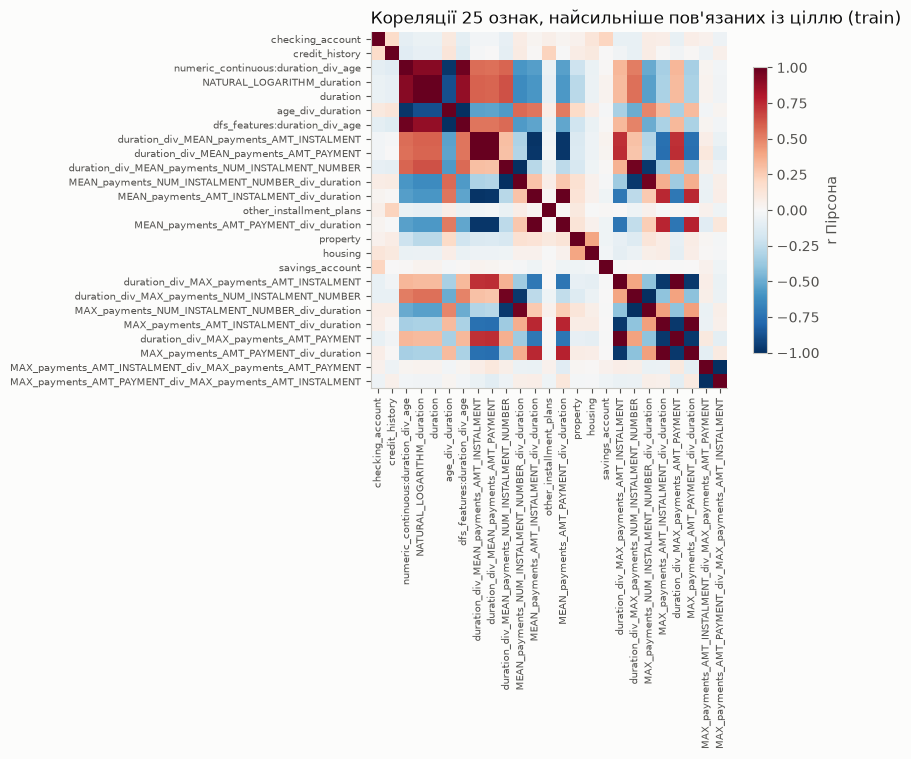

In [26]:
order = stats["corr_with_target"].index[:25]
C = Z_train[order].corr()
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(C, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(order)), order, rotation=90, fontsize=7); ax.set_yticks(range(len(order)), order, fontsize=7)
ax.grid(False); fig.colorbar(im, ax=ax, shrink=0.8, label="r Пірсона")
ax.set_title("Кореляції 25 ознак, найсильніше пов'язаних із ціллю (train)", loc="left")
fig.tight_layout(); fig.savefig(FIG / "basic_stats_correlation.png", dpi=130); plt.show()

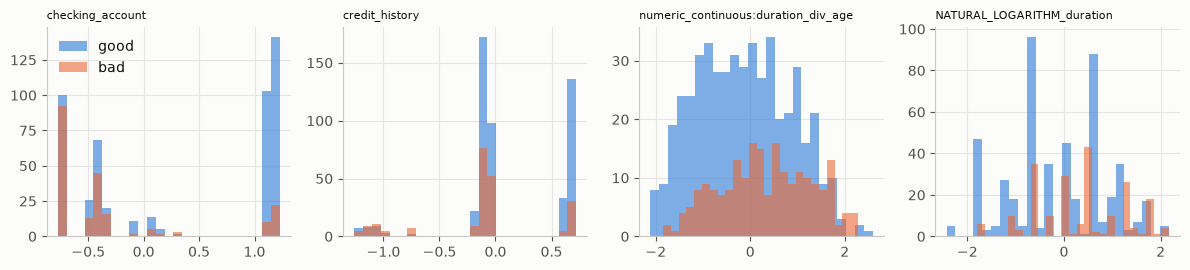

In [27]:
fig, axes = plt.subplots(1, 4, figsize=(12, 2.8))
for ax, col in zip(axes, stats["corr_with_target"].index[:4]):
    for cls, color, lab in ((0, BLUE, "good"), (1, ORANGE, "bad")):
        ax.hist(Z_train.loc[y_train == cls, col], bins=25, alpha=0.6, color=color, label=lab)
    ax.set_title(col, fontsize=8, loc="left")
axes[0].legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "basic_stats_distributions.png", dpi=130); plt.show()

## 7. Експеримент 3 — Extracted + AutoFE, чесний відбір


In [28]:
for model, cfg in (("LR", CFG["full_lr"]), ("RF", CFG["full_rf"])):
    t0 = time.time()
    pipe = model_pipeline(cfg, MODELS[model](), hybrid_selector(MODELS[model](), SEL)).fit(X_train, y_train)
    FITTED[("3. Extracted + AutoFE", model)] = pipe
    names = np.array(readable_names(pipe.named_steps["prep"].get_feature_names_out()))
    sel = pipe.named_steps["select"]
    kept = names[sel.named_steps["basic"].get_support()][sel.named_steps["filter"].get_support()]
    chosen = [str(kept[i]) for i in sel.named_steps["wrapper"].k_feature_idx_]
    record("3. Extracted + AutoFE", model, pipe.predict_proba(X_test)[:, 1], len(chosen),
           f"відбір у train: {len(names)} → {len(chosen)}")
    print(f"   {len(names)} ознак після препроцесингу → SFS обрав {len(chosen)} за {time.time()-t0:.0f} с:", chosen)

3. Extracted + AutoFE        LR: ROC-AUC = 0.7605  [95% CI 0.703–0.818], ознак: 15
   194 ознак після препроцесингу → SFS обрав 15 за 7 с: ['numeric_continuous:duration_div_age', 'checking_account', 'credit_history', 'property', 'other_installment_plans', 'housing', 'employment_since', 'complaint_text_svd3', 'complaint_weekday_cos', 'duration_div_credit_amount', 'NATURAL_LOGARITHM_age', 'NATURAL_LOGARITHM_duration', 'MEAN_payments_AMT_INSTALMENT_div_AMT_PAYMENT', 'MAX_payments_AMT_INSTALMENT_div_MAX_payments_AMT_PAYMENT', 'duration_div_MAX_payments_AMT_INSTALMENT']


3. Extracted + AutoFE        RF: ROC-AUC = 0.7568  [95% CI 0.696–0.808], ознак: 15
   223 ознак після препроцесингу → SFS обрав 15 за 211 с: ['numeric_continuous:duration_div_age', 'checking_account_0-200 DM', 'checking_account_<0 DM', 'checking_account_no account', 'credit_history_all paid at this bank', 'credit_history_critical account', 'credit_history_no credits / all paid', 'purpose_education', 'savings_account_unknown/none', 'property_real estate', 'other_installment_plans_none', 'age_div_credit_amount', 'MAX_payments_AMT_INSTALMENT_div_MAX_payments_AMT_PAYMENT', 'MAX_payments_AMT_INSTALMENT_div_duration', 'MAX_payments_AMT_PAYMENT_div_MAX_payments_AMT_INSTALMENT']


## 8. Експеримент 4 — Leaky Pipeline (навмисний витік)


In [29]:
LEAKY = {}
for model, cfg in (("LR", CFG["full_lr"]), ("RF", CFG["full_rf"])):
    prep = DynamicPipelineBuilder(str(cfg)).build()
    prep.fit(X, y)
    Z_all = prep.transform(X)
    selector = hybrid_selector(MODELS[model](), SEL)
    selector.fit(Z_all, y)
    Z_sel = selector.transform(Z_all)
    Z_tr, Z_te = Z_sel[idx_train], Z_sel[idx_test]
    clf = MODELS[model]().fit(Z_tr, y_train)
    names = np.array(readable_names(prep.get_feature_names_out()))
    kept = names[selector.named_steps["basic"].get_support()][selector.named_steps["filter"].get_support()]
    chosen = [str(kept[i]) for i in selector.named_steps["wrapper"].k_feature_idx_]
    LEAKY[model] = {"prep": prep, "chosen": chosen}
    record("4. Leaky Pipeline", model, clf.predict_proba(Z_te)[:, 1], len(chosen), "параметри й відбір до спліта")
    print("   SFS обрав:", chosen)

4. Leaky Pipeline            LR: ROC-AUC = 0.8606  [95% CI 0.813–0.903], ознак: 15
   SFS обрав: ['numeric_continuous:credit_amount_div_duration', 'numeric_continuous:duration_div_age', 'installment_rate', 'checking_account', 'credit_history', 'purpose', 'savings_account', 'property', 'other_installment_plans', 'housing', 'complaint_company', 'duration_div_credit_amount', 'MAX_payments_AMT_INSTALMENT_div_MAX_payments_AMT_PAYMENT', 'duration_div_MAX_payments_AMT_INSTALMENT', 'duration_div_MEAN_payments_AMT_INSTALMENT']


4. Leaky Pipeline            RF: ROC-AUC = 0.8161  [95% CI 0.759–0.868], ознак: 15
   SFS обрав: ['credit_amount', 'checking_account_0-200 DM', 'checking_account_<0 DM', 'checking_account_no account', 'credit_history_critical account', 'purpose_car (used)', 'purpose_education', 'property_unknown/none', 'other_installment_plans_none', 'housing_own', 'complaint_company', 'NATURAL_LOGARITHM_age', 'COUNT_payments_div_duration', 'MAX_payments_AMT_INSTALMENT_div_duration', 'MEAN_payments_AMT_INSTALMENT_div_duration']


### Що саме протекло — механізм

Найсильніший канал — **WoE компанії CFPB** (`complaint_company`, 212 значень, 109 трапляються один раз). Після `prep.fit(X, y)` ваги WoE кожної компанії містять мітки *усіх* її скарг, включно з тестовими. Для компанії з однією скаргою:

WoE = ln( (g + a)/(G + aK) ÷ (b + a)/(B + aK) ), де (g, b) = (1, 0) для good і (0, 1) для bad.

Тобто код рядка test — це монотонна функція його власної мітки: модель «прогнозує» ціль, яку їй передали в ознаці. SFS на всіх рядках відразу помітив, що ця ознака «відмінно» розділяє класи, і обрав її. Порівняння кодів компанії для тих самих тестових рядків:

AUC коду компанії щодо мітки test: чесний (WoE з train) = 0.486; з витоком (WoE з усіх даних) = 0.720


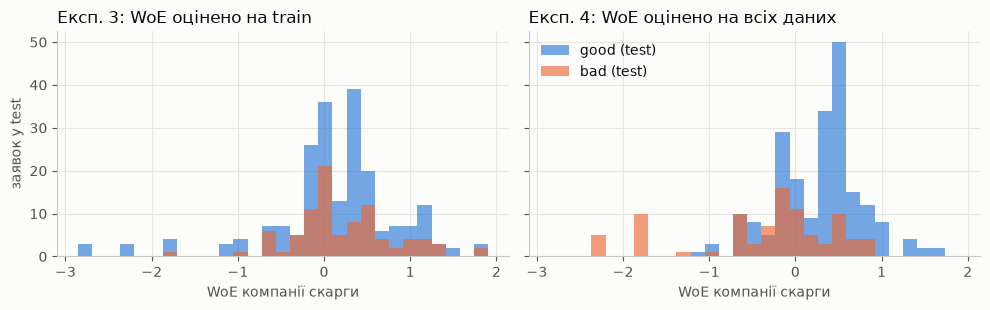

In [30]:
def company_codes(prep_fitted, rows):
    ct_branch = prep_fitted.named_transformers_["high_cardinality"]
    return ct_branch.transform(rows[["complaint_company"]])[:, 0]

honest_codes = company_codes(FITTED[("3. Extracted + AutoFE", "LR")].named_steps["prep"], X_test)
leaky_codes = company_codes(LEAKY["LR"]["prep"], X_test)
print(f"AUC коду компанії щодо мітки test: чесний (WoE з train) = {roc_auc_score(y_test, -honest_codes):.3f}; "
      f"з витоком (WoE з усіх даних) = {roc_auc_score(y_test, -leaky_codes):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for ax, codes, title in ((axes[0], honest_codes, "Експ. 3: WoE оцінено на train"),
                         (axes[1], leaky_codes, "Експ. 4: WoE оцінено на всіх даних")):
    bins = np.linspace(min(honest_codes.min(), leaky_codes.min()), max(honest_codes.max(), leaky_codes.max()), 30)
    ax.hist(codes[y_test == 0], bins=bins, alpha=0.65, color=BLUE, label="good (test)")
    ax.hist(codes[y_test == 1], bins=bins, alpha=0.65, color=ORANGE, label="bad (test)")
    ax.set_title(title, loc="left"); ax.set_xlabel("WoE компанії скарги")
axes[0].set_ylabel("заявок у test"); axes[1].legend(frameon=False, loc="upper left")
fig.tight_layout(); fig.savefig(FIG / "leakage_company_woe.png", dpi=130); plt.show()

## 9. Таблиця п'яти експериментів

In [31]:
res = pd.DataFrame(RESULTS)
res["95% CI"] = res.apply(lambda r: f"{r.ci_low:.3f}–{r.ci_high:.3f}", axis=1)
res.to_csv(ART / "experiments.csv", index=False)
res[["experiment", "model", "roc_auc", "95% CI", "n_features", "note"]].round(4)

,experiment,model,roc_auc,95% CI,n_features,note
0,0. Non-ML Heuristic,—,0.6897,0.629–0.747,3,"правило ЛР №1, без навчання"
1,1. Baseline,LR,0.7997,0.742–0.851,19,конфігурація ЛР №1
2,1. Baseline,RF,0.7739,0.717–0.826,50,конфігурація ЛР №1
3,2. Manual FE,LR,0.7796,0.720–0.833,21,"+ interactions, Yeo-Johnson, OOF WoE"
4,2. Manual FE,RF,0.7891,0.731–0.844,52,"+ interactions, Yeo-Johnson, OOF WoE"
5,3. Extracted + AutoFE,LR,0.7605,0.703–0.818,15,відбір у train: 194 → 15
6,3. Extracted + AutoFE,RF,0.7568,0.696–0.808,15,відбір у train: 223 → 15
7,4. Leaky Pipeline,LR,0.8606,0.813–0.903,15,параметри й відбір до спліта
8,4. Leaky Pipeline,RF,0.8161,0.759–0.868,15,параметри й відбір до спліта


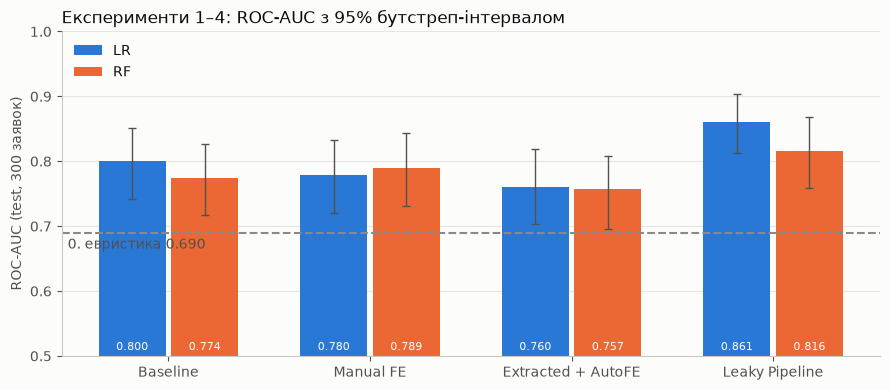

In [32]:
exps = [e for e in res["experiment"].unique() if not e.startswith("0.")]
x = np.arange(len(exps)); w = 0.36
fig, ax = plt.subplots(figsize=(9, 4))
for k, (model, color) in enumerate((("LR", BLUE), ("RF", ORANGE))):
    sub = res[res.model == model].set_index("experiment").loc[exps]
    ax.bar(x + (k - 0.5) * w, sub.roc_auc, w * 0.92, color=color, label=model,
           yerr=[sub.roc_auc - sub.ci_low, sub.ci_high - sub.roc_auc], capsize=3, error_kw={"ecolor": "#52514e", "lw": 1})
    for xi, v in zip(x, sub.roc_auc):
        ax.text(xi + (k - 0.5) * w, 0.505, f"{v:.3f}", ha="center", va="bottom", fontsize=8, color="#fcfcfb")
ax.axhline(auc_heuristic_test, color=GRAY, ls="--", lw=1.5)
ax.text(-0.5, auc_heuristic_test - 0.008, f"0. евристика {auc_heuristic_test:.3f}", ha="left", va="top", color="#52514e")
ax.set_xticks(x, [e.split(". ", 1)[1] for e in exps]); ax.set_ylim(0.5, 1.0); ax.set_ylabel("ROC-AUC (test, 300 заявок)")
ax.set_title("Експерименти 1–4: ROC-AUC з 95% бутстреп-інтервалом", loc="left")
ax.legend(frameon=False, loc="upper left"); ax.grid(axis="x", visible=False)
fig.tight_layout(); fig.savefig(FIG / "experiments_auc.png", dpi=130); plt.show()

In [33]:
def paired_delta(a, b, n_boot=2000, seed=0):
    rng = np.random.default_rng(seed); d = []
    for _ in range(n_boot):
        i = rng.integers(0, len(y_test), len(y_test))
        if y_test[i].min() != y_test[i].max():
            d.append(roc_auc_score(y_test[i], a[i]) - roc_auc_score(y_test[i], b[i]))
    d = np.array(d)
    return roc_auc_score(y_test, a) - roc_auc_score(y_test, b), *np.percentile(d, [2.5, 97.5]), (d <= 0).mean()

pairs = [(("1. Baseline", m), ("0. Non-ML Heuristic", "—")) for m in ("LR", "RF")]
for m in ("LR", "RF"):
    pairs += [(("2. Manual FE", m), ("1. Baseline", m)), (("3. Extracted + AutoFE", m), ("1. Baseline", m)),
              (("4. Leaky Pipeline", m), ("3. Extracted + AutoFE", m))]
rows = []
for a, b in pairs:
    delta, lo, hi, p = paired_delta(PRED[a], PRED[b])
    rows.append({"порівняння": f"{a[0]} [{a[1]}] − {b[0]} [{b[1]}]", "ΔAUC": delta, "95% CI": f"{lo:+.3f}…{hi:+.3f}", "p (Δ ≤ 0)": p})
deltas = pd.DataFrame(rows)
deltas.to_csv(ART / "paired_deltas.csv", index=False)
pd.DataFrame({f"{e} [{m}]": p for (e, m), p in PRED.items()} | {"y_test": y_test, "sex": sex_test},
             index=X_test.index).to_csv(ART / "test_predictions.csv")
deltas.round(4)

,порівняння,ΔAUC,95% CI,p (Δ ≤ 0)
0,1. Baseline [LR] − 0. Non-ML Heuristic [—],0.1101,+0.055…+0.167,0.0000
1,1. Baseline [RF] − 0. Non-ML Heuristic [—],0.0843,+0.028…+0.141,0.0035
2,2. Manual FE [LR] − 1. Baseline [LR],-0.0202,-0.039…-0.001,0.9775
3,3. Extracted + AutoFE [LR] − 1. Baseline [LR],-0.0393,-0.071…-0.004,0.9855
4,4. Leaky Pipeline [LR] − 3. Extracted + AutoFE...,0.1002,+0.056…+0.144,0.0000
5,2. Manual FE [RF] − 1. Baseline [RF],0.0152,-0.006…+0.037,0.0805
6,3. Extracted + AutoFE [RF] − 1. Baseline [RF],-0.0171,-0.065…+0.030,0.7635
7,4. Leaky Pipeline [RF] − 3. Extracted + AutoFE...,0.0593,+0.001…+0.120,0.0230


## 10. DPR і EOR для Експериментів 1 і 4 (перший, ненадійний розрахунок)


In [34]:
fair_rows = []
for exp in ("1. Baseline", "3. Extracted + AutoFE", "4. Leaky Pipeline"):
    for model in ("LR", "RF"):
        r = fairness_report(y_test, PRED[(exp, model)], sex_test, privileged=FAIR["privileged"],
                            threshold=EXP["decision_threshold"])
        fair_rows.append({"experiment": exp, "model": model, **r})
fair = pd.DataFrame(fair_rows)
fair.to_csv(ART / "fairness.csv", index=False)
print("у test:", pd.Series(sex_test).value_counts().to_dict())
fair.round(3)

у test: {'male': 199, 'female': 101}


,experiment,model,grant_rate_privileged,grant_rate_unprivileged,tpr_good_privileged,tpr_good_unprivileged,DPR,EOR
0,1. Baseline,LR,0.814,0.782,0.917,0.909,0.961,0.992
1,1. Baseline,RF,0.824,0.762,0.910,0.894,0.925,0.983
2,3. Extracted + AutoFE,LR,0.789,0.792,0.882,0.879,1.004,0.996
3,3. Extracted + AutoFE,RF,0.819,0.743,0.896,0.833,0.907,0.930
4,4. Leaky Pipeline,LR,0.749,0.762,0.903,0.924,1.018,1.024
5,4. Leaky Pipeline,RF,0.779,0.802,0.896,0.939,1.030,1.049


## 11. Трирівневий відбір: повна воронка (п. 4.5)


In [35]:
t0 = time.time()
funnel = SelectionFunnel(SEL, random_state=EXP["random_state"]).fit(Z_train, y_train)
print(f"воронка: {time.time()-t0:.0f} с")
counts = funnel.counts(); counts.to_csv(ART / "selection_funnel.csv")
counts.to_frame()

воронка: 8 с


,n_features
initial,194
basic_statistics,98
filter,30
hybrid_sfs,15
embedded_l1,13
tree_top,10


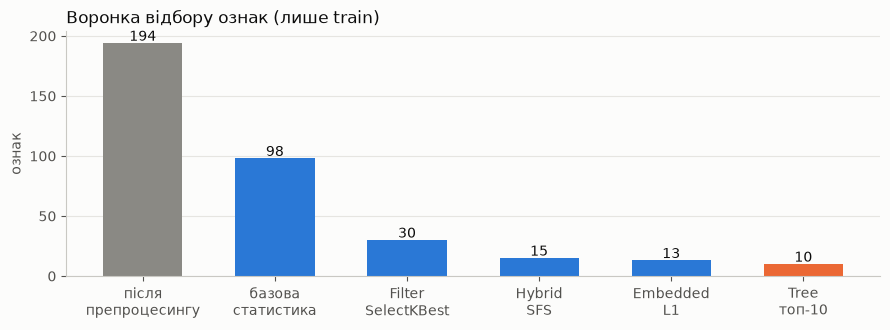

In [36]:
labels = ["після\nпрепроцесингу", "базова\nстатистика", "Filter\nSelectKBest", "Hybrid\nSFS", "Embedded\nL1", "Tree\nтоп-10"]
fig, ax = plt.subplots(figsize=(9, 3.4))
bars = ax.bar(labels, counts.values, color=[GRAY, BLUE, BLUE, BLUE, BLUE, ORANGE], width=0.6)
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 2, str(v), ha="center")
ax.set_ylabel("ознак"); ax.grid(axis="x", visible=False)
ax.set_title("Воронка відбору ознак (лише train)", loc="left")
fig.tight_layout(); fig.savefig(FIG / "selection_funnel.png", dpi=130); plt.show()

In [37]:
groups = {"sig_": "сигнал", "complaint_text": "текст", "complaint_month": "час", "complaint_weekday": "час",
          "complaint_company": "компанія CFPB"}
def origin(name):
    if name in src_of or name.startswith("dfs_features:"): return "DFS"
    for prefix, g in groups.items():
        if name.startswith(prefix): return g
    return "German Credit (+ручні)"
final = funnel.permutation_importance_.copy()
final["походження"] = [origin(n) for n in final.index]
final["L1 коефіцієнт"] = funnel.l1_coef_.reindex(final.index)
print("SFS (15):", funnel.stages_["hybrid_sfs"])
final.round(4)

SFS (15): ['numeric_continuous:duration_div_age', 'checking_account', 'credit_history', 'property', 'other_installment_plans', 'housing', 'employment_since', 'complaint_text_svd3', 'complaint_weekday_cos', 'duration_div_credit_amount', 'NATURAL_LOGARITHM_age', 'NATURAL_LOGARITHM_duration', 'MEAN_payments_AMT_INSTALMENT_div_AMT_PAYMENT', 'MAX_payments_AMT_INSTALMENT_div_MAX_payments_AMT_PAYMENT', 'duration_div_MAX_payments_AMT_INSTALMENT']


,mean,std,походження,L1 коефіцієнт
checking_account,0.1018,0.0258,German Credit (+ручні),-0.7692
credit_history,0.0370,0.0164,German Credit (+ручні),-0.4500
numeric_continuous:duration_div_age,0.0202,0.0134,German Credit (+ручні),0.1253
MEAN_payments_AMT_INSTALMENT_div_AMT_PAYMENT,0.0147,0.0066,DFS,0.0805
NATURAL_LOGARITHM_duration,0.0141,0.0085,DFS,0.2098
duration_div_MAX_payments_AMT_INSTALMENT,0.0111,0.0154,DFS,0.1023
other_installment_plans,0.0065,0.0074,German Credit (+ручні),-0.0432
employment_since,0.0049,0.0099,German Credit (+ручні),-0.0113
complaint_weekday_cos,0.0047,0.0065,час,-0.0268
property,0.0038,0.0043,German Credit (+ручні),-0.0190


In [38]:
sfs_top = set(funnel.stages_["hybrid_sfs"]); rfe_top = set(funnel.rfe_selected_)
print(f"Бонус: RFE(15) і SFS(15) збігаються в {len(sfs_top & rfe_top)} ознаках")
print("лише SFS:", sorted(sfs_top - rfe_top)); print("лише RFE:", sorted(rfe_top - sfs_top))
pd.Series({k: ", ".join(v) for k, v in funnel.stages_.items() if k != "initial"}).to_frame("ознаки").to_csv(ART / "selection_stages.csv")

Бонус: RFE(15) і SFS(15) збігаються в 10 ознаках
лише SFS: ['MEAN_payments_AMT_INSTALMENT_div_AMT_PAYMENT', 'complaint_text_svd3', 'complaint_weekday_cos', 'duration_div_MAX_payments_AMT_INSTALMENT', 'employment_since']
лише RFE: ['COUNT_payments_div_duration', 'NATURAL_LOGARITHM_credit_amount', 'duration_div_MEAN_payments_AMT_INSTALMENT', 'duration_div_MEAN_payments_NUM_INSTALMENT_NUMBER', 'savings_account']


## 12. Дані для REFORMS 3f: пропуски за класом цілі


In [39]:
audit = DynamicPipelineBuilder.audit_trail(prep_full)
miss = X_train[audit["feature"]].isna()
by_class = pd.DataFrame({"частка (аудит)": audit.set_index("feature")["missing_share"],
                         "good (y=0)": miss[y_train == 0].mean(), "bad (y=1)": miss[y_train == 1].mean(),
                         "правило": audit.set_index("feature")["strategy"] + audit.set_index("feature")["add_indicator"].map({True: " +I", False: ""})})
by_class = by_class[by_class["частка (аудит)"] > 0].sort_values("частка (аудит)", ascending=False)
by_class.to_csv(ART / "missing_by_class.csv")
print(f"колонок із пропусками на train: {len(by_class)} з {len(audit)}")
by_class.round(4).head(15)

колонок із пропусками на train: 148 з 165


,частка (аудит),good (y=0),bad (y=1),правило
residence_since,0.5086,0.5163,0.4905,constant +I
age_div_credit_amount,0.2429,0.2429,0.2429,median +I
credit_amount_div_age,0.2429,0.2429,0.2429,median +I
purpose,0.2357,0.2347,0.2381,constant
credit_amount_div_MEAN_payments_AMT_PAYMENT,0.2157,0.2163,0.2143,median +I
MAX_payments_NUM_INSTALMENT_NUMBER_div_credit_amount,0.2157,0.2163,0.2143,median +I
MEAN_payments_AMT_PAYMENT_div_credit_amount,0.2157,0.2163,0.2143,median +I
MEAN_payments_AMT_INSTALMENT_div_credit_amount,0.2157,0.2163,0.2143,median +I
credit_amount_div_MEAN_payments_AMT_INSTALMENT,0.2157,0.2163,0.2143,median +I
credit_amount_div_MAX_payments_NUM_INSTALMENT_NUMBER,0.2157,0.2163,0.2143,median +I


In [40]:
summary = {
    "heuristic_auc_test": auc_heuristic_test, "heuristic_auc_full": auc_heuristic_full,
    "sex_predictability_auc": sex_auc, "dfs": d, "signal_report": manifest["signal_report"],
    "vif_over_10": int((vif > 10).sum()), "vif_inf": int(np.isinf(vif).sum()),
    "high_corr_pairs": int(len(stats["high_corr_pairs"])), "space_after_prep": list(Z_train.shape),
    "leaky_chosen": {m: v["chosen"] for m, v in LEAKY.items()},
}
(ART / "summary.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False, default=float), encoding="utf-8")
print("артефакти збережено в", ART)

артефакти збережено в /home/roman/machine learning/lab_02/artifacts
